In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
from scipy.optimize import minimize
#from collections import defaultdict
import math
import glob, os
import scipy.optimize as optimize
from matplotlib.colors import LogNorm
from scipy.optimize import lsq_linear
import rdi_utils as jonas
import copy
import scipy.ndimage as nd
import time
import matplotlib.patches as patches


def flux_uJy_to_Wm(wl,flux) :
    return np.array(flux)/(333564095198152064*np.array(wl)**2)

def flux_Wm_to_uJy(wl,flux) :
    return np.array(flux)*(333564095198152064*np.array(wl)**2)

In [18]:
# doc a faire
# fait le post processing des données corono MIRI à partir du stage 2 en RDI, PCA et CombL
class postprocess_nircam_coro:
    def __init__(self, name, fil, pidsci, obssci, pidref, obsref, path_data, path_save, mask_lcomb, suffix):
        self.name      = name
        self.fil       = fil
        self.pids      = "{:05d}".format(pidsci)
        self.pidr      = "{:05d}".format(pidref)
        self.obssci    = "{:03d}".format(obssci)
        self.obsref    = "{:03d}".format(obsref)
        self.path_data = path_data
        self.path_save = path_save
        self.mask      = mask_lcomb
        self.suffix    = suffix
    
        
    def quick_reduction(self, new_dim=201, met_RDI=True, met_PCA=True, met_lcomb=True, dither=0):   
        
        if self.fil == "F200W": 
            lam = 2.0e-6 #µm
            x0  = 120.25
            y0  = 112.03
        if self.fil == "F444W": 
            lam = 4.44e-6 #µm
            x0  = 119.77
            y0  = 112.16
   
        sci_fi     = glob.glob(self.path_data+"P"+self.pids+"/obs"+self.obssci+"/jw*_"+self.suffix+".fits")
        ref_fi     = glob.glob(self.path_data+"P"+self.pidr+"/obs"+self.obsref+"/jw*_"+self.suffix+".fits")

        sci_fi.sort()
        ref_fi.sort()
        
        sci = fits.open(sci_fi[0])[1].data
        ref = []
        for i in ref_fi: ref.append(fits.open(i)[1].data)
        ref = np.array(ref)
        
        sci_c = imp.clean_image_nan(sci)  
        #sci_c = imp.clean_image_nan(imp.remove_bad_pixel(sci,3,5))  
        ref_c = []
        for i in range(len(ref_fi)): ref_c.append(ref[i,:,:])
        #for i in range(len(ref_fi)): ref_c.append(imp.remove_bad_pixel(ref[i,:,:],3,5))
        ref_c = np.array(ref_c)
        ref_c = imp.clean_image_nan(ref_c)


        newd = 320
        Y, X = np.ogrid[:newd, :newd]
        mask_pla   = np.sqrt((X - newd//2 + 0.5)**2 + (Y - newd//2 + 0.5)**2)
        dr = 2
        ### Std dev azimutale dans un anneau de 2 pix de largeur
        mean_sci      = np.ndarray(round(np.max(mask_pla)))
        mean_ref      = np.ndarray(round(np.max(mask_pla)))
        for i in range(0,round(np.max(mask_pla))):
            mask_sel          = (mask_pla >= i-dr) * (mask_pla < i+dr)
            mean_sci[i]       = np.nanmean(sci[mask_sel])  ### radial 
            mean_ref[i]       = np.nanmean(ref[0][mask_sel])  ### radial 




        bkg_sci = np.nanmean(mean_sci[-20:-10])
        bkg_ref = np.nanmean(mean_ref[-20:-10])

        sci_c -= bkg_sci
        ref_c -= bkg_ref
                

        annuli_bins = np.array([0, 10, 20, 30, 40, 50, 100, 320])
        mask   = np.sqrt((X - newd//2 + 0.5)**2 + (Y - newd//2 + 0.5)**2)
        mask_pca = []
        for i in range(len(annuli_bins)-1):
            mask_pca.append((mask>annuli_bins[i]) * (mask<=annuli_bins[i+1]))
            


    
        if met_PCA:
            PCA = imp.sub_PCA(sci_c, ref_c, [new_dim/2,new_dim/2], 2, dim=new_dim/2, plot=False)
            # PCA   = imp.remove_bad_pixel(PCA, 3,5)
            imp.save_fits(PCA  , self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_PCA.fits")
            PCA_J = imp.apply_pca(sci_c,    list(ref_c),    pca_masks = mask_pca,    sharpness = 0,    n_components = None)
            imp.save_fits(PCA_J  , self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_PCA_J.fits")



        if met_RDI:
            # flux scaling for RDI
            flux_ref = np.nanmean(np.nansum(np.nansum(ref_c,axis=2),axis=1))
            flux_sci = np.nansum(sci_c)
            f_scale = flux_sci/flux_ref
            print("f_scale with total flux : ",f_scale)
            RDI    = imp.RDI_classic(sci_c, ref_c, f_scale=f_scale)
            #RDI mais avec 1 seul dither (le meilleur)
            f_scale = flux_sci/np.nansum(ref_c[dither])
            print("f_scale with total flux : ",f_scale)
            RDI_1d = imp.RDI_classic(sci_c, ref_c[dither], f_scale=f_scale)
            # RDI   = imp.remove_bad_pixel(RDI, 3,5)
            imp.save_fits(RDI   , self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_RDI.fits")
            imp.save_fits(RDI_1d, self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_RDI_1d.fits")
        
        if met_lcomb:
            lcomb = imp.MIRI_linear_comb_mask(sci_c, ref_c, self.mask, use_minimize=False)
            # lcomb = imp.remove_bad_pixel(lcomb, 3,5)
            imp.save_fits(lcomb, self.path_save+self.name+"_"+self.fil+"_P"+self.pids+"_"+self.obssci+"_LComb.fits")


In [19]:
path_d = "/home/cperrot/Work/raw/JWST/Target/MAST/"
path_s = "/home/cperrot/Work/raw/JWST/Target/MAST/P03337/RDI/"
newd = 320
Y, X = np.ogrid[:newd, :newd]

mask = np.sqrt((X - newd/2)**2 + (Y-newd/2)**2) >= 50
obs01 = postprocess_nircam_coro("14her", "F200W", 3337, 1 , 3337, 3 , path_d, path_s, mask, "nrca2_cal")
obs02 = postprocess_nircam_coro("14her", "F444W", 3337, 2 , 3337, 3 , path_d, path_s, mask, "nrcalong_cal")
obs01.quick_reduction(new_dim = newd, met_lcomb=True, met_PCA=True, dither=0)
obs02.quick_reduction(new_dim = newd, met_lcomb=True, met_PCA=True, dither=0)


f_scale with total flux :  0.4453117
f_scale with total flux :  0.44792104
f_scale with total flux :  0.42897728
f_scale with total flux :  0.47177148


In [3]:

sci = fits.open("/home/cperrot/Work/raw/JWST/Target/MAST/P03337/obs001/jw03337001001_05101_00001_nrca2_cal.fits")[1].data
ref_fi     = glob.glob("/home/cperrot/Work/raw/JWST/Target/MAST/P03337/obs003/jw*nrca2_cal.fits")
ref = []
for i in ref_fi: ref.append(fits.open(i)[1].data)


7.323009e+06
7.27666e+06
7.155669e+06
7.1901905e+06
7.233466e+06
7.181335e+06
7.2573985e+06
7.196944e+06
7.1743945e+06
3.1821868e+06
7.2210075e+06
9.432016 3.9021132


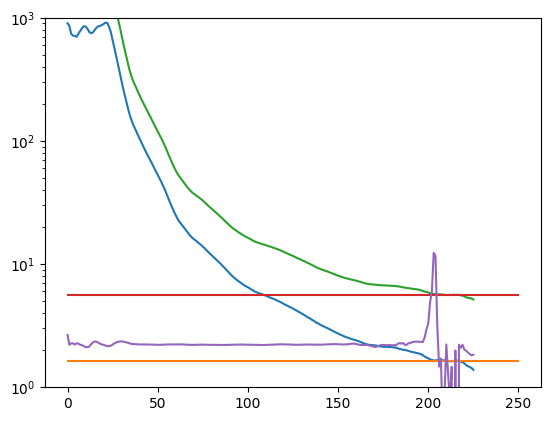

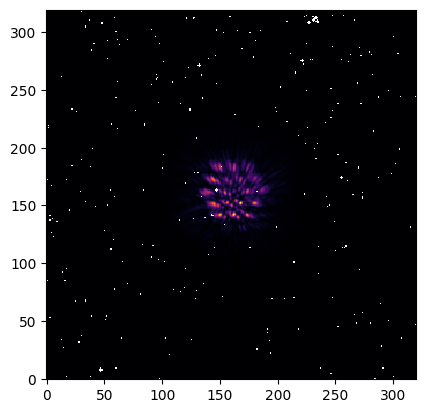

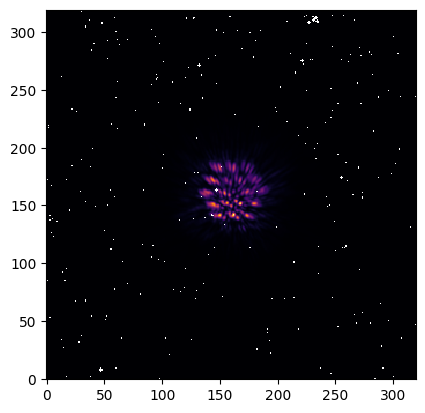

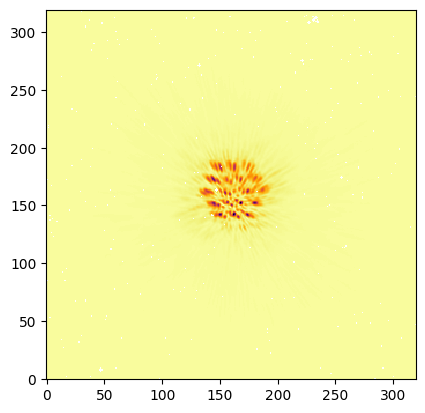

In [39]:
for i in ref:
    print(np.nansum(i))
print(np.nansum(sci))
print(np.nanmean(np.nansum(np.nansum(ref,axis=2),axis=1)))

bkg_sci = np.nanmedian(sci)
bkg_ref = np.nanmedian(ref)

print(bkg_ref,bkg_sci)



mask_pla   = np.sqrt((X - newd//2 + 0.5)**2 + (Y - newd//2 + 0.5)**2)
dr = 2
### Std dev azimutale dans un anneau de 2 pix de largeur
mean_sci      = np.ndarray(round(np.max(mask_pla)))
mean_ref      = np.ndarray(round(np.max(mask_pla)))
ref_test = ref[0]
for i in range(0,round(np.max(mask_pla))):
    mask_sel          = (mask_pla >= i-dr) * (mask_pla < i+dr)
    mean_sci[i]            = np.nanmean(sci[mask_sel])  ### radial 
    mean_ref[i]            = np.nanmean(ref[0][mask_sel])  ### radial 

plt.plot(mean_sci)
plt.plot([0,250],[np.mean(mean_sci[-20:-10]),np.mean(mean_sci[-20:-10])])
plt.plot(mean_ref)
plt.plot([0,250],[np.mean(mean_ref[-20:-10]),np.mean(mean_ref[-20:-10])])
plt.plot((mean_ref-np.mean(mean_ref[-20:-10]))/(mean_sci-np.mean(mean_sci[-20:-10])))
plt.yscale("log")
plt.ylim(1e-0,1e3)
plt.show()

plt.imshow(ref[0]-bkg_ref,origin='lower',cmap='inferno',interpolation='none')
plt.show()
plt.imshow(sci-bkg_sci,origin='lower',cmap='inferno',interpolation='none')
plt.show()
plt.imshow((sci-bkg_sci)-(ref[0]-bkg_ref),origin='lower',cmap='inferno',interpolation='none')
plt.show()


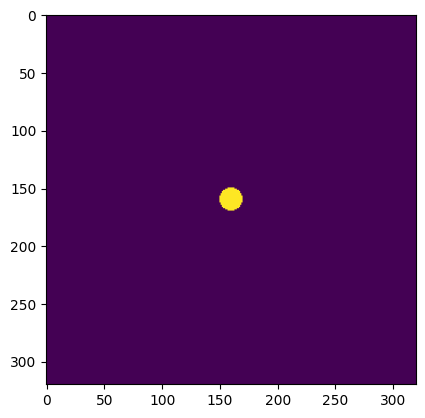

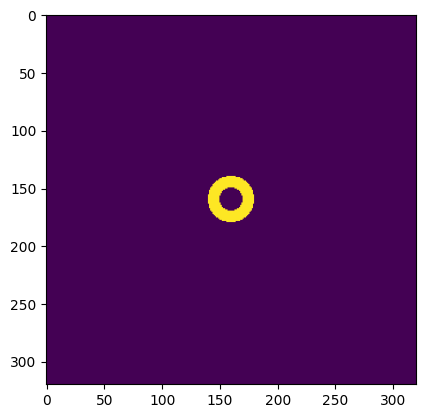

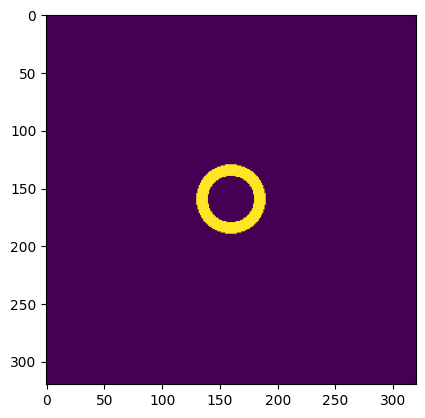

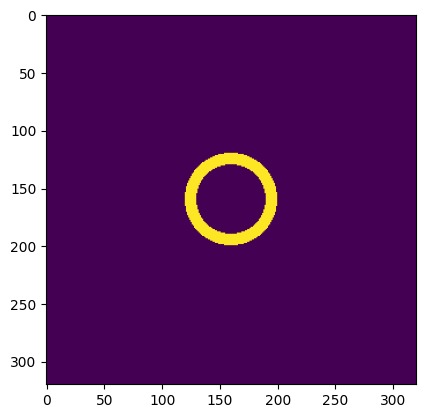

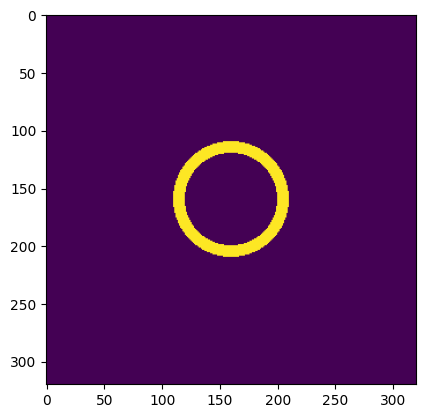

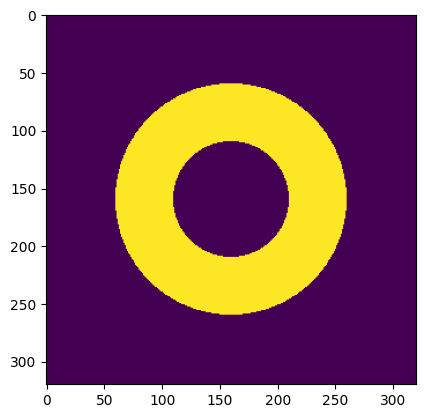

array([  0. ,   0.2,   0.5,   0.8,   1.1,   1.5, 100. ])